# Ecuación diferencial de segundo orden

Resuelve con SymPy $y'' + 4y - 3 = 0$, con $y(0) = 2$ e $y'(0) = 0$, y dibuja la solución.

Librerías: `conda install -n profesia numpy sympy matplotlib ipywidgets`

Eq(y(x), 5*cos(2*x)/4 + 3/4)

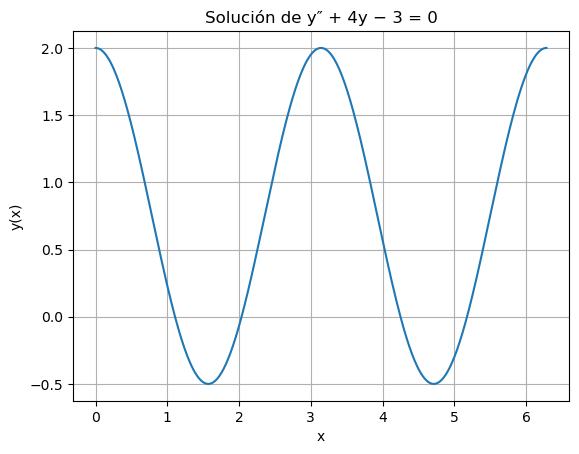

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

x = sp.symbols("x")
y = sp.Function("y")

ecuacion = sp.Eq(sp.diff(y(x), x, 2) + 4 * y(x) - 3, 0)
solucion = sp.dsolve(ecuacion, ics={y(0): 2, sp.diff(y(x), x).subs(x, 0): 0})

display(solucion)

f = sp.lambdify(x, solucion.rhs, "numpy")
valores_x = np.linspace(0, 2 * np.pi, 500)

plt.plot(valores_x, f(valores_x))
plt.xlabel("x")
plt.ylabel("y(x)")
plt.title("Solución de y″ + 4y − 3 = 0")
plt.grid(True)
plt.show()

## Generalización: $y'' + a\,y - 3 = 0$, con $y(0) = 2$ e $y'(0) = b$

Según el signo de $a$ la solución oscila ($a > 0$, cosenos), crece ($a < 0$, cosenos
hiperbólicos) o es una parábola ($a = 0$). Usa `x`, `y` y `valores_x` de la celda anterior.

In [2]:
import ipywidgets as widgets
from IPython.display import clear_output, display


def mostrar_solucion(a_val, b_val):
    """Muestra y dibuja la solución para a = a_val, b = b_val."""
    clear_output(wait=True)

    if a_val == 0:
        expr = 2 + b_val * x + sp.Rational(3, 2) * x**2
    elif a_val > 0:
        raiz = sp.sqrt(sp.Float(a_val))
        expr = (
            3 / sp.Float(a_val)
            + (2 - 3 / sp.Float(a_val)) * sp.cos(raiz * x)
            + b_val / raiz * sp.sin(raiz * x)
        )
    else:
        raiz = sp.sqrt(sp.Float(-a_val))
        expr = (
            3 / sp.Float(a_val)
            + (2 - 3 / sp.Float(a_val)) * sp.cosh(raiz * x)
            + b_val / raiz * sp.sinh(raiz * x)
        )

    display(sp.Eq(y(x), sp.simplify(expr)))

    funcion = sp.lambdify(x, expr, modules="numpy")
    valores_y = funcion(valores_x)

    plt.figure(figsize=(8, 4))
    plt.plot(valores_x, valores_y)
    plt.xlabel("x")
    plt.ylabel("y(x)")
    plt.title(f"Solución para a={a_val:.1f}, b={b_val:.1f}")
    plt.grid(True)
    plt.show()


slider_a = widgets.FloatSlider(value=1.0, min=-5.0, max=5.0, step=0.1, description="a")
slider_b = widgets.FloatSlider(value=0.0, min=-5.0, max=5.0, step=0.1, description="b")

salida = widgets.interactive_output(
    mostrar_solucion, {"a_val": slider_a, "b_val": slider_b}
)
display(widgets.VBox([slider_a, slider_b]), salida)

Output()